In [3]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
print(sys.path[0])

/home/benjamin-rodriguez/Desktop/PredictionMarkets


In [33]:
from ingest.polymarket import get_polymarket_data, _extract_category


df = get_polymarket_data(2099)

for _, row in df.iterrows():
    if _extract_category(row) is None: 
        print("Hi")


connecting to Polymarket API...
Successfully fetched 2099 events from Polymarket API.


In [34]:
import pandas as pd
from db.connection import get_conn

with get_conn() as conn:
    df = pd.read_sql("""
        SELECT
            CASE WHEN resolved = true THEN 'resolved' ELSE 'active/open' END AS status,
            CASE WHEN category IS NULL THEN 'NULL' ELSE 'has_category' END AS cat,
            COUNT(*) AS n
        FROM markets
        GROUP BY status, cat
        ORDER BY status, cat
    """, conn)
print(df.to_string(index=False))

     status          cat     n
active/open has_category 18280
active/open         NULL   168
   resolved has_category  2341
   resolved         NULL  1757


/tmp/ipykernel_469069/4013724354.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("""


In [21]:
from analysis.calibration import build_calibration_data, calibration_curve, plot_calibration

calibration_data = build_calibration_data(horizon_days=2, wiggle_hours=48)
print(calibration_data)

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 3081 resolved markets, 103 with usable observation, 2910 dropped (no snapshot in window)
    market_id  observation_price                 observation_time  days_before_resolution  outcome
0     1087905             0.0035 2026-06-16 09:41:56.869718+00:00                2.004839        0
1     1087908             0.0025 2026-06-16 11:27:29.759484+00:00                2.003869        0
2     1087927             0.0015 2026-06-16 09:26:52.380306+00:00                2.000181        0
3     1088137             0.0015 2026-06-16 17:59:41.025115+00:00                2.002245        0
4     1285765             0.4600 2026-06-18 23:13:42.767947+00:00                0.813058        1
..        ...                ...                              ...                     ...      ...
98     906975             0.0015 2026-06-15 22:18:18.794869+00:00                1.959968        0
99     947220             0.9870 2026-06-18 12:08:37.955241+00:00                2.001378        1
100   

In [22]:
import pandas as pd
from analysis.calibration import build_calibration_data

# see what variables have most data in order to write code that we can use later. 

def sweep_horizon_wiggle(
    horizons: list[float],
    wiggles: list[float],
) -> pd.DataFrame:
    """
    Try every (horizon, wiggle) combo and report yield + quality metrics.

    Quality here = how many observations sit at a genuinely uncertain price
    (0.05 < p < 0.95) rather than already snapped to the boundary. High raw
    yield with low 'uncertain' count means you're mostly grabbing
    already-resolved markets — fine for code-testing, misleading for analysis.
    """
    results = []
    for h in horizons:
        for w in wiggles:
            df = build_calibration_data(horizon_days=h, wiggle_hours=w)
            if df.empty:
                results.append({
                    "horizon_days": h, "wiggle_hours": w,
                    "n_total": 0, "n_uncertain": 0,
                    "pct_uncertain": float("nan"),
                    "median_days_off_target": float("nan"),
                })
                continue

            uncertain = df[(df["observation_price"] > 0.05) & (df["observation_price"] < 0.95)]
            days_off = (df["days_before_resolution"] - h).abs().median()

            results.append({
                "horizon_days": h,
                "wiggle_hours": w,
                "n_total": len(df),
                "n_uncertain": len(uncertain),
                "pct_uncertain": round(100 * len(uncertain) / len(df), 1),
                "median_days_off_target": round(days_off, 3),
            })

    out = pd.DataFrame(results).sort_values(["horizon_days", "wiggle_hours"])
    return out

In [25]:
horizons = [0.5, 1, 2, 3, 5]
wiggles  = [6, 12, 24, 48]

sweep = sweep_horizon_wiggle(horizons, wiggles)
print(sweep.to_string(index=False))

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 3305 resolved markets, 134 with usable observation, 2947 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 3305 resolved markets, 144 with usable observation, 2937 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


...

[calibration] 3305 resolved markets, 14 with usable observation, 3067 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 3305 resolved markets, 27 with usable observation, 3054 dropped (no snapshot in window)


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 3305 resolved markets, 54 with usable observation, 3027 dropped (no snapshot in window)
 horizon_days  wiggle_hours  n_total  n_uncertain  pct_uncertain  median_days_off_target
          0.5             6      134           77           57.5                   0.003
          0.5            12      144           82           56.9                   0.003
          0.5            24      145           83           57.2                   0.003
          0.5            48      148           83           56.1                   0.003
          1.0             6      126           79           62.7                   0.003
          1.0            12      133           82           61.7                   0.003
          1.0            24      147           89           60.5                   0.003
          1.0            48      148           89           60.1                   0.003
          2.0             6       90           58           64.4                   0.004
        

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:213: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


[calibration] 3305 resolved markets, 148 with usable observation, 2933 dropped (no snapshot in window)
          bin  mean_price  empirical_yes  n       se
(-0.001, 0.1]    0.024870       0.018519 54 0.018346
   (0.1, 0.2]    0.148000       0.000000 10 0.000000
   (0.2, 0.3]    0.241929       0.190476 21 0.085689
   (0.3, 0.4]    0.363125       0.250000  4 0.216506
   (0.4, 0.5]    0.467438       0.625000  8 0.171163
   (0.5, 0.6]    0.556700       0.800000  5 0.178885
   (0.6, 0.7]    0.647500       0.833333 12 0.107583
   (0.7, 0.8]    0.731875       0.500000  4 0.250000
   (0.8, 0.9]    0.875136       0.909091 11 0.086678
   (0.9, 1.0]    0.965368       1.000000 19 0.000000


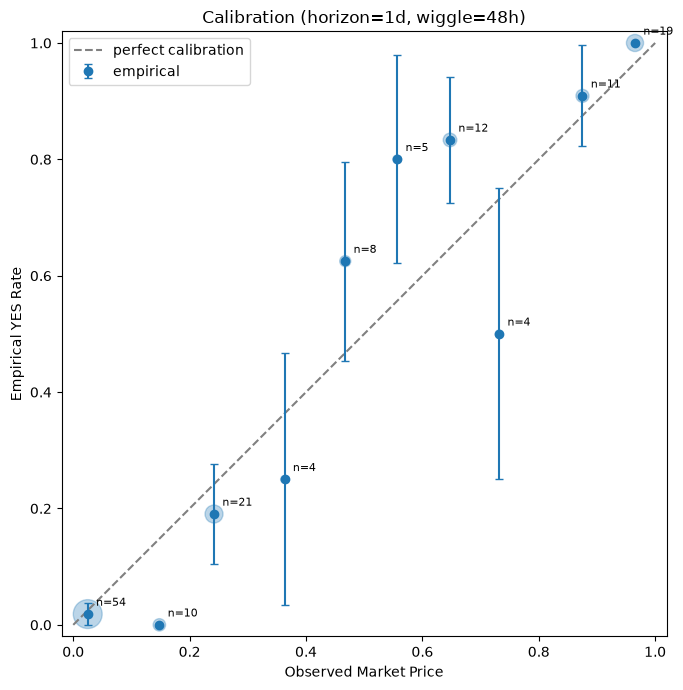

In [ ]:
horizon, tol = 3, 12

calibration_data = build_calibration_data(horizon_days=horizon, wiggle_hours=tol)

curve = calibration_curve(calibration_data, n_bins=10)
print(curve[["bin", "mean_price", "empirical_yes", "n", "se"]].to_string(index=False))

plot_calibration(curve, title=f"Calibration (horizon={horizon}d, wiggle={tol}h)")

In [4]:
import pandas as pd
from db.connection import get_conn

with get_conn() as conn:
    # Distribution of snapshot counts per market
    dist = pd.read_sql("""
        WITH counts AS (
            SELECT market_id, COUNT(*) AS n_snaps
            FROM market_snapshots
            WHERE mid_price IS NOT NULL          -- usable snapshots only
            GROUP BY market_id
        )
        SELECT
            COUNT(*) AS total_markets,
            COUNT(*) FILTER (WHERE n_snaps >= 30)  AS ge_30,
            COUNT(*) FILTER (WHERE n_snaps >= 50)  AS ge_50,
            COUNT(*) FILTER (WHERE n_snaps >= 100) AS ge_100,
            COUNT(*) FILTER (WHERE n_snaps >= 200) AS ge_200,
            ROUND(AVG(n_snaps)) AS avg_snaps,
            MAX(n_snaps) AS max_snaps
        FROM counts
    """, conn)

print("=== SNAPSHOT COUNT DISTRIBUTION (markets with usable mid) ===")
print(dist.to_string(index=False))

/tmp/ipykernel_945632/326671611.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dist = pd.read_sql("""


=== SNAPSHOT COUNT DISTRIBUTION (markets with usable mid) ===
 total_markets  ge_30  ge_50  ge_100  ge_200  avg_snaps  max_snaps
         22890  22752  22659   22546   22239     2646.0       3766


In [5]:
with get_conn() as conn:
    span = pd.read_sql("""
        WITH stats AS (
            SELECT market_id,
                   COUNT(*) AS n_snaps,
                   MAX(snapshot_at) - MIN(snapshot_at) AS time_span,
                   EXTRACT(EPOCH FROM (MAX(snapshot_at) - MIN(snapshot_at)))
                       / NULLIF(COUNT(*) - 1, 0) / 60.0 AS avg_gap_minutes
            FROM market_snapshots
            WHERE mid_price IS NOT NULL
            GROUP BY market_id
            HAVING COUNT(*) >= 50
        )
        SELECT
            COUNT(*) AS markets_50plus,
            ROUND(AVG(EXTRACT(EPOCH FROM time_span)/86400.0)::numeric, 1) AS avg_span_days,
            ROUND(AVG(avg_gap_minutes)::numeric, 1) AS avg_gap_min,
            ROUND(MIN(avg_gap_minutes)::numeric, 1) AS min_gap_min,
            ROUND(MAX(avg_gap_minutes)::numeric, 1) AS max_gap_min
        FROM stats
    """, conn)
print("\n=== FOR MARKETS WITH 50+ SNAPSHOTS ===")
print(span.to_string(index=False))

/tmp/ipykernel_945632/2302977334.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  span = pd.read_sql("""



=== FOR MARKETS WITH 50+ SNAPSHOTS ===
 markets_50plus  avg_span_days  avg_gap_min  min_gap_min  max_gap_min
          22659           31.9         17.6         14.6        396.1
